In [ ]:
import os
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/MPT"

DATA_RAW_DIR = f"{PROJECT_DIR}/data/raw"
DATA_PROCESSED_DIR = f"{PROJECT_DIR}/data/processed"
FIGURES_DIR = f"{PROJECT_DIR}/figures"
OUTPUTS_DIR = f"{PROJECT_DIR}/outputs"

for folder in [DATA_RAW_DIR, DATA_PROCESSED_DIR, FIGURES_DIR, OUTPUTS_DIR]:
    os.makedirs(folder, exist_ok=True)

print("Project folders are ready.")
print("Project location:", PROJECT_DIR)

Project folders are ready.
Project location: /content/drive/MyDrive/MPT


In [ ]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from pathlib import Path

SEED, TRADING_DAYS = 42, 252

np.random.seed(42)
#pd.set_option("display.max_columns", 30)
#plt.rcParams["figure.figsize"] = (10, 5)
#plt.rcParams["axes.grid"] = True
#plt.rcParams["grid.alpha"] = 0.25


In [ ]:
#Define the historical period
START_DATE = "2015-01-01"
END_DATE = pd.Timestamp.today().strftime("%Y-%m-%d")


In [ ]:
# ============================================================
# DOWNLOAD MULTI-ASSET ETF DATA
# ============================================================
# auto_adjust=True provides adjusted historical prices suitable
# for total-return-style calculations.
# ============================================================

portfolio_tickers = ["SPY", "VXUS", "IEF", "LQD", "GLD", "VNQ"]

prices_raw = yf.download(
    tickers=portfolio_tickers,
    start=START_DATE,
    end=END_DATE,
    interval="1d",
    auto_adjust=True,
    progress=False
)

# Extract closing prices while handling possible MultiIndex format.
if isinstance(prices_raw.columns, pd.MultiIndex):
    prices = prices_raw["Close"].copy()
else:
    prices = prices_raw.copy()

# Keep only dates where every ETF has a valid price.
prices = prices.dropna().sort_index()

print(f"Portfolio observations: {len(prices):,}")
print(f"Portfolio start date:   {prices.index.min().date()}")
print(f"Portfolio end date:     {prices.index.max().date()}")

prices.head()

Portfolio observations: 2,963
Portfolio start date:   2015-01-02
Portfolio end date:     2026-10-14


Ticker,GLD,IEF,LQD,SPY,VNQ,VXUS
Date,,,,,,
2015-01-02,114.080002,81.462982,79.104134,169.267517,51.642838,34.354366
2015-01-05,115.800003,81.960030,79.427536,166.210617,51.925507,33.599007
2015-01-06,117.120003,82.510574,79.750999,164.645111,52.440529,33.342476
2015-01-07,116.430000,82.495262,79.856606,166.696762,53.244499,33.734406
2015-01-08,115.940002,82.158798,79.599174,169.654755,53.445492,34.161957


In [ ]:

# Step 2: Calculate daily ETF returns

# Calculate percentage returns from one trading day to the next
returns = prices.pct_change().dropna()

# Display the first five daily return observations
print("Daily Returns:")
display(returns.head())

Daily Returns:


Ticker,GLD,IEF,LQD,SPY,VNQ,VXUS
Date,,,,,,
2015-01-05,0.015077,0.006102,0.004088,-0.018060,0.005474,-0.021987
2015-01-06,0.011399,0.006717,0.004072,-0.009419,0.009918,-0.007635
2015-01-07,-0.005891,-0.000186,0.001324,0.012461,0.015331,0.011755
2015-01-08,-0.004209,-0.004079,-0.003224,0.017745,0.003775,0.012674
2015-01-09,0.011385,0.004933,0.002654,-0.008013,0.000470,-0.004172


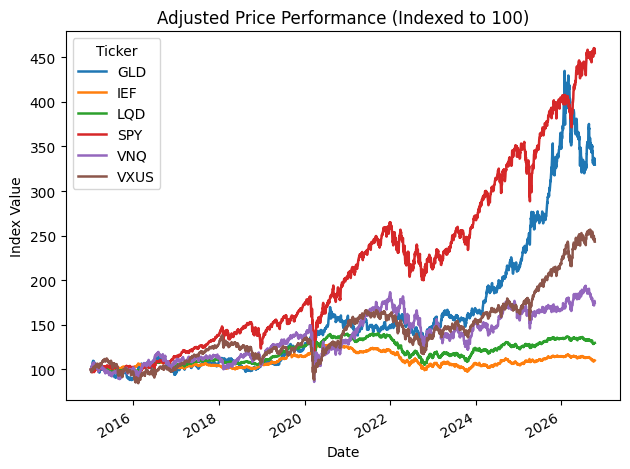

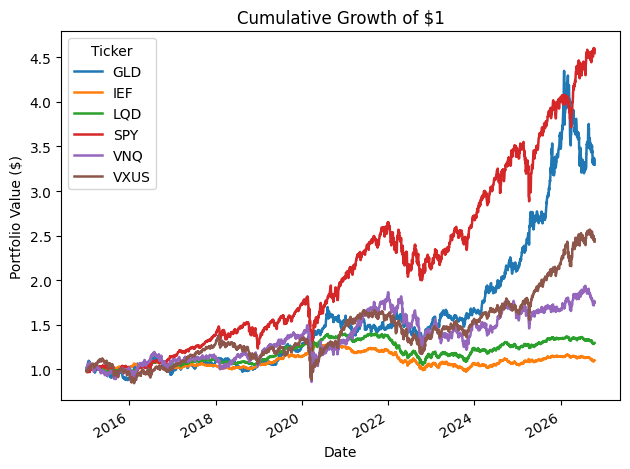

In [ ]:
price_indexed = prices / prices.iloc[0] * 100
ax = price_indexed.plot(linewidth=1.8)
ax.set_title("Adjusted Price Performance (Indexed to 100)")
ax.set_xlabel("Date")
ax.set_ylabel("Index Value")
plt.tight_layout(); plt.show()
ax = ((1 + returns).cumprod()).plot(linewidth=1.8)
ax.set_title("Cumulative Growth of $1")
ax.set_xlabel("Date")
ax.set_ylabel("Portfolio Value ($)")
plt.tight_layout(); plt.show()


In [ ]:

# Calculate the average daily return for each ETF
mean_daily_returns = returns.mean()

# Annualize the average daily returns
expected_returns = mean_daily_returns * 252

print("Estimated Annual Returns:")
display(expected_returns.to_frame(name="Expected Annual Return"))

Estimated Annual Returns:


,Expected Annual Return
Ticker,
GLD,0.114767
IEF,0.010341
LQD,0.025613
SPY,0.144243
VNQ,0.068094
VXUS,0.090574


In [ ]:

# Calculate daily standard deviation for each ETF
daily_volatility = returns.std()

# Convert daily volatility into annualized volatility
annualized_volatility = daily_volatility * np.sqrt(252)

print("Annualized Volatility:")
display(annualized_volatility.to_frame(name="Annualized Volatility"))


Annualized Volatility:


,Annualized Volatility
Ticker,
GLD,0.162724
IEF,0.065394
LQD,0.082974
SPY,0.175117
VNQ,0.201469
VXUS,0.172217


In [ ]:

# Calculate the daily covariance matrix
daily_covariance = returns.cov()

# Annualize the covariance matrix
cov_matrix = daily_covariance * 252

print("Annualized Covariance Matrix:")
display(cov_matrix)


Annualized Covariance Matrix:


Ticker,GLD,IEF,LQD,SPY,VNQ,VXUS
Ticker,,,,,,
GLD,0.026479,0.003550,0.003979,0.002084,0.004147,0.005885
IEF,0.003550,0.004276,0.003919,-0.001594,0.001180,-0.000966
LQD,0.003979,0.003919,0.006885,0.004048,0.006570,0.004223
SPY,0.002084,-0.001594,0.004048,0.030666,0.025026,0.025594
VNQ,0.004147,0.001180,0.006570,0.025026,0.040590,0.022158
VXUS,0.005885,-0.000966,0.004223,0.025594,0.022158,0.029659


ETF Correlation Matrix:


Ticker,GLD,IEF,LQD,SPY,VNQ,VXUS
Ticker,,,,,,
GLD,1.000000,0.333564,0.294730,0.073140,0.126499,0.210016
IEF,0.333564,1.000000,0.722285,-0.139219,0.089587,-0.085733
LQD,0.294730,0.722285,1.000000,0.278581,0.393027,0.295509
SPY,0.073140,-0.139219,0.278581,1.000000,0.709352,0.848676
VNQ,0.126499,0.089587,0.393027,0.709352,1.000000,0.638616
VXUS,0.210016,-0.085733,0.295509,0.848676,0.638616,1.000000


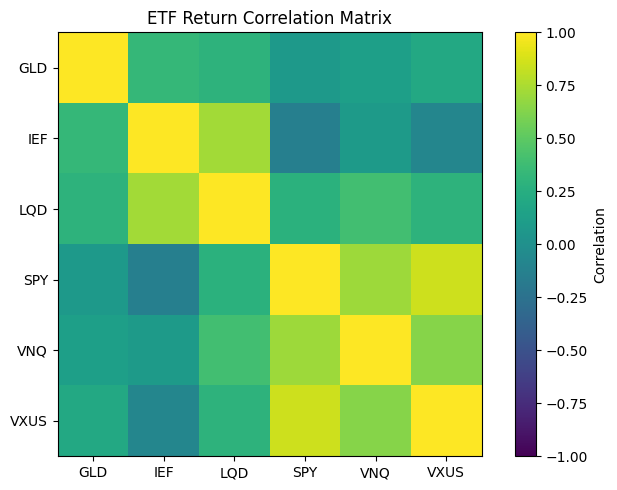

In [ ]:

# Calculate the correlation matrix using daily returns
correlation_matrix = returns.corr()

print("ETF Correlation Matrix:")
display(correlation_matrix)

# Visualize the correlation matrix
plt.figure(figsize=(7, 5))

plt.imshow(correlation_matrix, vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)
plt.yticks(
    range(len(correlation_matrix.index)),
    correlation_matrix.index
)

plt.title("ETF Return Correlation Matrix")
plt.tight_layout()
plt.show()


In [ ]:

# Combine annual return and volatility estimates into one summary table
risk_return_summary = pd.DataFrame({
    "Expected Annual Return": expected_returns,
    "Annualized Volatility": annualized_volatility
})

print("MPT Risk and Return Summary:")
display(risk_return_summary)


MPT Risk and Return Summary:


,Expected Annual Return,Annualized Volatility
Ticker,,
GLD,0.114767,0.162724
IEF,0.010341,0.065394
LQD,0.025613,0.082974
SPY,0.144243,0.175117
VNQ,0.068094,0.201469
VXUS,0.090574,0.172217


,Annualized Return (%),Annualized Volatility (%),Daily Volatility (%)
Ticker,,,
GLD,11.477,16.272,1.025
IEF,1.034,6.539,0.412
LQD,2.561,8.297,0.523
SPY,14.424,17.512,1.103
VNQ,6.809,20.147,1.269
VXUS,9.057,17.222,1.085


Ticker,GLD,IEF,LQD,SPY,VNQ,VXUS
Ticker,,,,,,
GLD,1.000,0.334,0.295,0.073,0.126,0.210
IEF,0.334,1.000,0.722,-0.139,0.090,-0.086
LQD,0.295,0.722,1.000,0.279,0.393,0.296
SPY,0.073,-0.139,0.279,1.000,0.709,0.849
VNQ,0.126,0.090,0.393,0.709,1.000,0.639
VXUS,0.210,-0.086,0.296,0.849,0.639,1.000


Ticker,GLD,IEF,LQD,SPY,VNQ,VXUS
Ticker,,,,,,
GLD,0.026479,0.003550,0.003979,0.002084,0.004147,0.005885
IEF,0.003550,0.004276,0.003919,-0.001594,0.001180,-0.000966
LQD,0.003979,0.003919,0.006885,0.004048,0.006570,0.004223
SPY,0.002084,-0.001594,0.004048,0.030666,0.025026,0.025594
VNQ,0.004147,0.001180,0.006570,0.025026,0.040590,0.022158
VXUS,0.005885,-0.000966,0.004223,0.025594,0.022158,0.029659


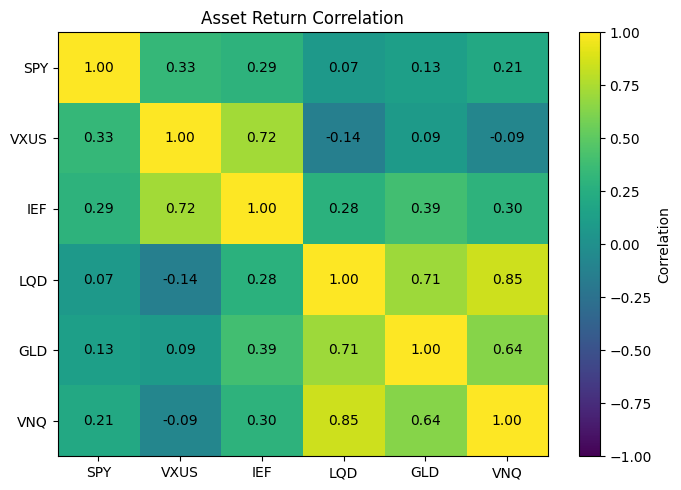

In [ ]:
asset_summary = pd.DataFrame({"Annualized Return (%)": expected_returns*100,
    "Annualized Volatility (%)": annualized_volatility*100,
    "Daily Volatility (%)": daily_volatility*100})
display(asset_summary.round(3))
display(correlation_matrix.round(3))
display(cov_matrix.round(6))
fig, ax = plt.subplots(figsize=(7,5))
im = ax.imshow(correlation_matrix.to_numpy(), vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(portfolio_tickers)), portfolio_tickers); ax.set_yticks(range(len(portfolio_tickers)), portfolio_tickers)
ax.set_title("Asset Return Correlation")
for i in range(len(portfolio_tickers)):
    for j in range(len(portfolio_tickers)):
        ax.text(j, i, f"{correlation_matrix.iloc[i,j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Correlation"); plt.tight_layout(); plt.show()


#Portfolio Constructions

Equal Weight Portfolio


## Portfolio Construction: Equal Weight vs. Global Minimum Variance

This section constructs and compares two **long-only, fully invested portfolios**:

1. **Equal-Weight (EW) Portfolio**
2. **Global Minimum-Variance (GMV) Portfolio**

The purpose is to understand how portfolio weights affect expected return and risk, and how diversification can reduce overall portfolio volatility.

---

### 1. Equal-Weight Portfolio

The equal-weight portfolio allocates the same proportion of capital to every asset, regardless of its expected return, volatility, or correlation with other assets.

The weight assigned to each asset is:

$$
w_i = \frac{1}{N}
$$

where:

- \(w_i\) is the portfolio weight of asset \(i\).
- \(N\) is the total number of assets.

**Example:** If the portfolio contains six assets, each asset receives an equal allocation:

$$
w_i = \frac{1}{6} \approx 0.1667 = 16.67\%
$$

The weights satisfy the full-investment condition:

$$
\sum_{i=1}^{N} w_i = 1
$$

**Interpretation:** Equal weighting is simple, transparent, and easy to implement. It provides a useful benchmark against which more sophisticated portfolio-allocation methods can be evaluated.

However, equal weighting does not explicitly account for differences in asset risk or correlations.

---

### 2. Global Minimum-Variance (GMV) Portfolio

The global minimum-variance portfolio seeks the allocation that minimizes total portfolio variance, subject to specified investment constraints.

Its optimization problem is:

$$
\boxed{
\begin{aligned}
\min_{\mathbf{w}} \quad
& \mathbf{w}^{\top}\boldsymbol{\Sigma}\mathbf{w} \\
\text{subject to} \quad
& \sum_{i=1}^{N} w_i = 1 \\
& w_i \geq 0,\quad i=1,\ldots,N
\end{aligned}
}
$$

where:$$(\mathbf{w})$$is the vector of portfolio weights.
- $$(\boldsymbol{\Sigma})$$is the covariance matrix of asset returns.
- $$(\mathbf{w}^{\top})$$ is  the transpose of the weight vector.
- (N) is the number of assets.


The GMV portfolio uses the covariance matrix to account for both individual asset risk and the relationships between assets.

**Important:** The GMV portfolio does not directly maximize expected return. Its objective is to minimize estimated portfolio variance while satisfying the investment constraints.

#### How the optimization works

The optimizer evaluates different combinations of portfolio weights and searches for the allocation with the lowest estimated variance.

In Python, `scipy.optimize.minimize` with the **SLSQP (Sequential Least Squares Programming)** method can solve this constrained optimization problem. SLSQP supports equality constraints, bounds, and nonlinear objective functions.

The resulting weights depend on the estimated covariance matrix and the constraints imposed on the portfolio.

---

### 3. Portfolio Expected Return

The expected portfolio return is the weighted average of the expected returns of the individual assets.

In summation notation:

$$
E[R_p] = \sum_{i=1}^{N} w_i \mu_i
$$

In matrix notation:

$$
\boxed{E[R_p] = \mathbf{w}^{\top}\boldsymbol{\mu}}
$$

where:

- \(E[R_p]\) is the expected return of the portfolio.
- \(w_i\) is the weight of asset \(i\).
- \(\mu_i\) is the expected return of asset \(i\).
- \(\boldsymbol{\mu}\) is the vector of expected asset returns.

**Interpretation:** An asset with a larger portfolio weight contributes more to the portfolio's

In [ ]:
# ============================================================
# PORTFOLIO CONSTRUCTION: EQUAL WEIGHT VS GLOBAL MINIMUM VARIANCE
# ============================================================
#
# This cell constructs and compares two long-only portfolios:
#
#   1. Equal-weight portfolio
#      - Allocates the same percentage to every asset.
#      - Requires no return or covariance estimates.
#
#   2. Global minimum-variance (GMV) portfolio
#      - Uses the covariance matrix to find the allocation
#        with the lowest estimated portfolio variance.
#      - Does not require expected-return estimates.
#
# Both portfolios satisfy:
#   - Fully invested: weights sum to 100%.
#   - Long-only: no negative weights.
#
# Inputs expected from Notebook 1:
#   expected_returns : Series or array of asset expected returns
#   cov_matrix       : annualized covariance matrix
#   asset_names      : list of asset tickers or names
# ============================================================

from scipy.optimize import minimize
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. PORTFOLIO RETURN FUNCTION
# ------------------------------------------------------------
def portfolio_return(weights, means=expected_returns):
    """
    Calculate the expected return of a portfolio.

    Formula:
        E[Rp] = sum(weight_i * expected_return_i)

    Parameters
    ----------
    weights : array-like
        Portfolio weights. They should sum to 1.
    means : Series or array-like
        Expected returns for each asset.

    Returns
    -------
    float
        Expected portfolio return.
    """
    weights = np.asarray(weights, dtype=float)
    means = np.asarray(means, dtype=float)

    # Matrix multiplication calculates the weighted average return.
    return float(weights @ means)


# ------------------------------------------------------------
# 2. PORTFOLIO VOLATILITY FUNCTION
# ------------------------------------------------------------
def portfolio_volatility(weights, covariance=cov_matrix):
    """
    Calculate the annualized volatility of a portfolio.

    Formula:
        portfolio variance = w' * covariance matrix * w
        portfolio volatility = sqrt(portfolio variance)

    Parameters
    ----------
    weights : array-like
        Portfolio weights. They should sum to 1.
    covariance : DataFrame or array-like
        Annualized covariance matrix of asset returns.

    Returns
    -------
    float
        Annualized portfolio volatility.
    """
    weights = np.asarray(weights, dtype=float)
    covariance = np.asarray(covariance, dtype=float)

    # Calculate portfolio variance: w' Sigma w.
    portfolio_variance = weights @ covariance @ weights

    # Use max(..., 0) to avoid a tiny negative value caused by
    # numerical rounding.
    return float(np.sqrt(max(portfolio_variance, 0.0)))


# ------------------------------------------------------------
# 3. GLOBAL MINIMUM-VARIANCE OPTIMIZER
# ------------------------------------------------------------
def optimize_gmv(covariance):
    """
    Find the global minimum-variance portfolio weights.

    Objective:
        Minimize portfolio variance:
            minimize w' * covariance * w

    Constraints:
        - Weights sum to 1.
        - Each weight is between 0 and 1 (long-only).

    Parameters
    ----------
    covariance : DataFrame or array-like
        Annualized covariance matrix of asset returns.

    Returns
    -------
    numpy.ndarray
        Optimal GMV portfolio weights.
    """
    covariance = np.asarray(covariance, dtype=float)
    n_assets = covariance.shape[0]

    # Start from an equal-weight portfolio.
    initial_weights = np.ones(n_assets) / n_assets

    result = minimize(
        # Objective: minimize portfolio variance.
        fun=lambda w: float(w @ covariance @ w),

        # Initial guess: equal weights.
        x0=initial_weights,

        # SLSQP supports bounds and equality constraints.
        method="SLSQP",

        # Long-only constraint: each weight is between 0 and 1.
        bounds=[(0.0, 1.0)] * n_assets,

        # Fully invested constraint: weights must sum to 1.
        constraints=[
            {
                "type": "eq",
                "fun": lambda w: np.sum(w) - 1.0,
            }
        ],

        # Optimization settings.
        options={
            "maxiter": 2000,
            "ftol": 1e-12,
        },
    )

    # Raise an error if the optimizer did not converge.
    if not result.success:
        raise RuntimeError(result.message)

    return result.x


# ------------------------------------------------------------
# 4. CONSTRUCT THE TWO PORTFOLIOS WEIGHTS
# ------------------------------------------------------------
# Number of assets in the investment universe.
asset_names=list(returns.columns)
n_assets = len(asset_names)

# Equal-weight portfolio: each asset receives 1 / n_assets.
equal_weights = np.ones(n_assets) / n_assets

# GMV portfolio: optimizer chooses weights to minimize variance.
gmv_weights = optimize_gmv(cov_matrix)

# ------------------------------------------------------------
# 5. CREATE A COMPARISON TABLE
# ------------------------------------------------------------
weights_table = pd.DataFrame(
    {
        "Equal-weight": equal_weights,
        "Global Minimum Variance": gmv_weights,
    },
    index=asset_names,
)

# Add portfolio-level statistics.
weights_table.loc["Expected Return"] = [
    portfolio_return(equal_weights),
    portfolio_return(gmv_weights),
]

weights_table.loc["Volatility"] = [
    portfolio_volatility(equal_weights),
    portfolio_volatility(gmv_weights),
]

# Display weights and portfolio statistics.
display(weights_table.round(4))

,Equal-weight,Global Minimum Variance
GLD,0.1667,0.0000
IEF,0.1667,0.8415
LQD,0.1667,0.0000
SPY,0.1667,0.1284
VNQ,0.1667,0.0000
VXUS,0.1667,0.0300
Expected Return,0.0756,0.0299
Volatility,0.0997,0.0580


In [ ]:
# ============================================================
# 4. MINIMUM-VARIANCE PORTFOLIO FOR A TARGET RETURN
# ============================================================

def optimize_target_return(target, means, covariance):
    """
    Find the minimum-variance portfolio for a given target return.

    Parameters
    ----------
    target : float
        Required expected portfolio return.
    means : array-like
        Expected returns for each asset.
    covariance : DataFrame or array-like
        Covariance matrix of asset returns.

    Returns
    -------
    numpy.ndarray or None
        Optimized portfolio weights, or None if optimization fails.
    """

    # Determine the number of assets.
    n_assets = len(means)

    # Start the search from an equally weighted portfolio.
    initial_weights = np.ones(n_assets) / n_assets

    # Objective: minimize portfolio variance.
    objective = lambda weights: float(
        weights @ covariance @ weights
    )

    # Constraint 1: the portfolio must be fully invested.
    full_investment_constraint = {
        "type": "eq",
        "fun": lambda weights: np.sum(weights) - 1.0
    }

    # Constraint 2: expected return must equal the target.
    target_return_constraint = {
        "type": "eq",
        "fun": lambda weights: float(
            weights @ means
        ) - target
    }

    # Long-only bounds for every asset.
    bounds = [(0.0, 1.0)] * n_assets

    # Solve the constrained minimum-variance problem.
    result = minimize(
        objective,
        initial_weights,
        method="SLSQP",
        bounds=bounds,
        constraints=[
            full_investment_constraint,
            target_return_constraint
        ],
        options={
            "maxiter": 2000,
            "ftol": 1e-11
        }
    )

    # Return the solution only if the optimizer succeeds.
    if result.success:
        return result.x

    return None

In [ ]:
# ============================================================
# 5. GENERATE EFFICIENT-FRONTIER PORTFOLIOS
# ============================================================

# Create 60 target returns between the smallest and largest
# individual asset expected returns.
target_returns = np.linspace(
    expected_returns.min(),
    expected_returns.max(),
    60
)

# Store the results for each successfully optimized portfolio.
frontier = []

# Solve the optimization problem for every target return.
for target in target_returns:

    # Find the minimum-variance allocation for this target.
    weights = optimize_target_return(
        target=target,
        means=expected_returns,
        covariance=cov_matrix
    )

    # Skip targets for which the optimizer did not succeed.
    if weights is None:
        continue

    # Calculate the portfolio's expected return and volatility.
    expected_return = portfolio_return(
        weights,
        means=expected_returns
    )

    volatility = portfolio_volatility(
        weights,
        covariance=cov_matrix
    )

    # Save the portfolio metrics and individual asset weights.
    portfolio_result = {
        "Target Return": target,
        "Expected Return": expected_return,
        "Volatility": volatility
    }

    # Add a separate column for each asset's portfolio weight.
    portfolio_result.update(
        {
            f"Weight {asset}": weight
            for asset, weight in zip(asset_names, weights)
        }
    )

    # Append this portfolio to the frontier results.
    frontier.append(portfolio_result)

# Convert the results into a DataFrame for analysis and plotting.
efficient_frontier = pd.DataFrame(frontier)

# Display the first few optimized portfolios.
display(efficient_frontier.head().round(4))

# Report how many target-return portfolios were successfully found.
print(
    f"Successfully optimized "
    f"{len(efficient_frontier)} out of "
    f"{len(target_returns)} target returns."
)

,Target Return,Expected Return,Volatility,Weight GLD,Weight IEF,Weight LQD,Weight SPY,Weight VNQ,Weight VXUS
0,0.0103,0.0103,0.0654,0.0,1.0000,0.0,0.0000,0.0,0.0000
1,0.0126,0.0126,0.0633,0.0,0.9717,0.0,0.0000,0.0,0.0283
2,0.0149,0.0149,0.0616,0.0,0.9434,0.0,0.0000,0.0,0.0566
3,0.0171,0.0171,0.0604,0.0,0.9151,0.0,0.0000,0.0,0.0849
4,0.0194,0.0194,0.0596,0.0,0.8919,0.0,0.0076,0.0,0.1005


Successfully optimized 60 out of 60 target returns.


In [ ]:

from scipy.optimize import minimize

# Number of assets
n_assets = len(expected_returns)

# Convert inputs to NumPy arrays
mu = expected_returns.to_numpy(dtype=float)
Sigma = cov_matrix.to_numpy(dtype=float)

# Objective function: portfolio variance
def portfolio_variance_function(weights):
    return weights @ Sigma @ weights

# Constraint: weights must sum to 1
constraints = [
    {"type": "eq", "fun": lambda weights: np.sum(weights) - 1}
]

# Long-only bounds: each weight must be between 0 and 1
bounds = [(0, 1)] * n_assets

# Equal-weight starting point
initial_weights = np.ones(n_assets) / n_assets

# Optimize the portfolio
gmv_result = minimize(
    portfolio_variance_function,
    initial_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={"maxiter": 2000, "ftol": 1e-12}
)

# Check whether optimization succeeded
if not gmv_result.success:
    raise RuntimeError(gmv_result.message)

# Store optimal weights
gmv_weights = gmv_result.x

# Calculate optimized portfolio return and volatility
gmv_return = gmv_weights @ mu
gmv_variance = gmv_weights @ Sigma @ gmv_weights
gmv_volatility = np.sqrt(gmv_variance)

# Display the results
gmv_weights_series = pd.Series(
    gmv_weights,
    index=expected_returns.index,
    name="Optimal Weight"
)

print("Global Minimum-Variance Portfolio Weights:")
display(gmv_weights_series.to_frame().style.format("{:.2%}"))

print(f"Expected Annual Return: {gmv_return:.2%}")
print(f"Annualized Volatility: {gmv_volatility:.2%}")


Global Minimum-Variance Portfolio Weights:


,Optimal Weight
Ticker,
GLD,0.00%
IEF,84.15%
LQD,0.00%
SPY,12.84%
VNQ,0.00%
VXUS,3.00%


Expected Annual Return: 2.99%
Annualized Volatility: 5.80%


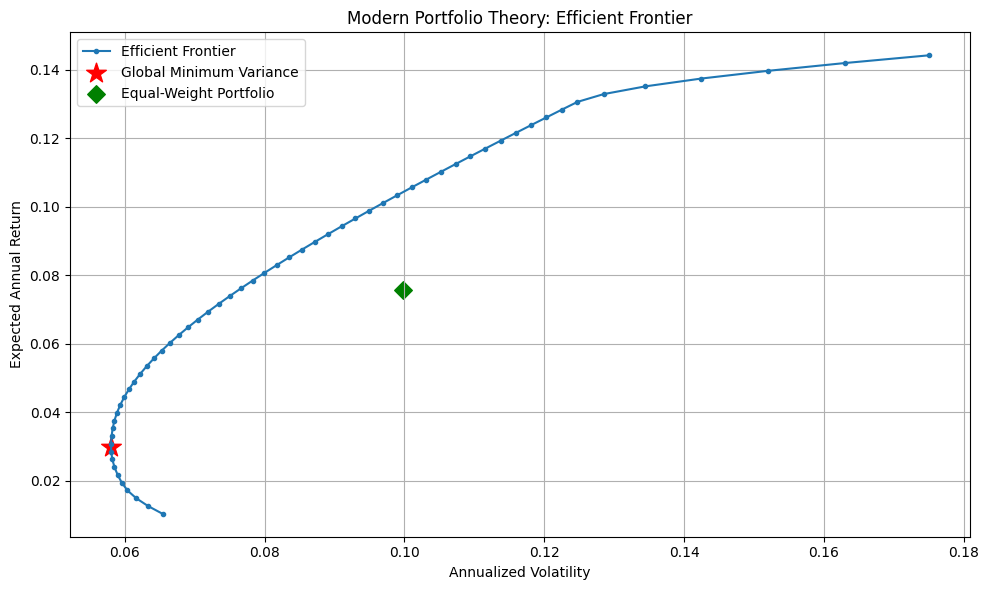

In [ ]:
# Calculate equal-weight portfolio statistics.
equal_weight_return = portfolio_return(equal_weights)
equal_weight_volatility = portfolio_volatility(equal_weights)

# Calculate GMV portfolio statistics.
gmv_return = portfolio_return(gmv_weights)
gmv_volatility = portfolio_volatility(gmv_weights)

# Plot the efficient frontier.
plt.figure(figsize=(10, 6))

plt.plot(
    efficient_frontier["Volatility"],
    efficient_frontier["Expected Return"],
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="Efficient Frontier",
)

# Mark the global minimum-variance portfolio.
plt.scatter(
    gmv_volatility,
    gmv_return,
    marker="*",
    s=220,
    color="red",
    label="Global Minimum Variance",
)

# Mark the equal-weight portfolio.
plt.scatter(
    equal_weight_volatility,
    equal_weight_return,
    marker="D",
    s=80,
    color="green",
    label="Equal-Weight Portfolio",
)

plt.title("Modern Portfolio Theory: Efficient Frontier")
plt.xlabel("Annualized Volatility")
plt.ylabel("Expected Annual Return")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# VALUE AT RISK (VaR) AND CONDITIONAL VALUE AT RISK (CVaR)
# ============================================================
#
# This section measures the downside risk of an equal-weight
# multi-asset portfolio using three approaches:
#
#   1. Historical VaR and CVaR
#      - Uses the actual historical return distribution.
#
#   2. Parametric VaR and CVaR
#      - Assumes daily portfolio returns are normally distributed.
#
#   3. Monte Carlo VaR and CVaR
#      - Simulates many future daily returns from a normal
#        distribution calibrated to historical mean and volatility.
#
# Definitions:
#   - VaR: the loss threshold at a chosen confidence level.
#   - CVaR / Expected Shortfall: the average loss beyond VaR.
#
# Losses are defined as:
#       loss = -portfolio return
#
# Therefore, a positive loss represents a decline in portfolio value.
# ============================================================

from scipy.stats import norm


# ------------------------------------------------------------
# 1. CREATE THE EQUAL-WEIGHT PORTFOLIO
# ------------------------------------------------------------

# Calculate daily simple returns from adjusted prices.
returns = prices.pct_change().dropna()

# Store asset names in a list.
asset_names = list(returns.columns)

# Number of assets in the portfolio.
n_assets = len(asset_names)

# Equal-weight allocation: each asset receives 1 / n_assets.
equal_weights = np.ones(n_assets) / n_assets

# Daily portfolio return is the weighted sum of asset returns.
equal_weight_returns = returns @ equal_weights

# Display the first few portfolio returns.
display(equal_weight_returns.head())

,0
Date,
2015-01-05,-0.001551
2015-01-06,0.002509
2015-01-07,0.005799
2015-01-08,0.003780
2015-01-09,0.001209


In [ ]:
# ============================================================
# 2. HISTORICAL VaR AND CVaR
# ============================================================
#
# Historical VaR uses the empirical distribution of past
# portfolio losses. It does not assume returns are normal.
#
# Historical CVaR is the average loss among the worst outcomes
# beyond the VaR threshold.
# ============================================================

def historical_var_cvar(losses, confidence=0.95):
    """
    Calculate historical VaR and CVaR.

    Parameters
    ----------
    losses : array-like or Series
        Daily portfolio losses, calculated as -portfolio return.
    confidence : float
        Confidence level, such as 0.95 or 0.99.

    Returns
    -------
    tuple
        (historical VaR, historical CVaR)
    """
    # Convert losses to a Series and remove missing observations.
    losses = pd.Series(losses).dropna()

    if losses.empty:
        raise ValueError("No loss observations available.")

    # Historical VaR is the empirical loss quantile.
    var = float(losses.quantile(confidence))

    # Select all losses at or beyond the VaR threshold.
    tail_losses = losses[losses >= var]

    # CVaR is the average loss in that tail.
    cvar = (
        float(tail_losses.mean())
        if len(tail_losses) > 0
        else var
    )

    return var, cvar


# Convert portfolio returns into losses.
historical_losses = -equal_weight_returns

# Calculate one-day 95% historical VaR and CVaR.
historical_var_95, historical_cvar_95 = historical_var_cvar(
    losses=historical_losses,
    confidence=0.95,
)

print(f"Historical 95% VaR:  {historical_var_95:.4%}")
print(f"Historical 95% CVaR: {historical_cvar_95:.4%}")

Historical 95% VaR:  0.9092%
Historical 95% CVaR: 1.4514%


In [ ]:
# ============================================================
# 3. PARAMETRIC VaR AND CVaR
# ============================================================
#
# Parametric VaR assumes daily portfolio returns follow a
# normal distribution.
#
# For a normal distribution:
#
#   VaR = -(mu - z * sigma)
#
# where:
#   mu    = mean daily return
#   sigma = standard deviation of daily returns
#   z     = standard-normal quantile at the confidence level
#
# CVaR under normality is:
#
#   CVaR = -mu + sigma * pdf(z) / (1 - confidence)
# ============================================================

def parametric_var_cvar(portfolio_returns, confidence=0.95):
    """
    Calculate parametric VaR and CVaR assuming normal returns.

    Parameters
    ----------
    portfolio_returns : array-like or Series
        Historical daily portfolio returns.
    confidence : float
        Confidence level, such as 0.95 or 0.99.

    Returns
    -------
    tuple
        (parametric VaR, parametric CVaR)
    """
    # Clean the return series.
    returns_series = pd.Series(portfolio_returns).dropna()

    if returns_series.empty:
        raise ValueError("No portfolio returns available.")

    # Estimate daily mean and standard deviation.
    mean_return = float(returns_series.mean())
    return_volatility = float(returns_series.std(ddof=1))

    # Standard-normal quantile for the chosen confidence level.
    z_score = norm.ppf(confidence)

    # Parametric VaR.
    var = float(-mean_return + return_volatility * z_score)

    # Parametric CVaR under the normal-distribution assumption.
    cvar = float(
        -mean_return
        + return_volatility
        * norm.pdf(z_score)
        / (1 - confidence)
    )

    return var, cvar


# Calculate one-day 95% parametric VaR and CVaR.
parametric_var_95, parametric_cvar_95 = parametric_var_cvar(
    portfolio_returns=equal_weight_returns,
    confidence=0.95,
)

print(f"Parametric 95% VaR:  {parametric_var_95:.4%}")
print(f"Parametric 95% CVaR: {parametric_cvar_95:.4%}")

Parametric 95% VaR:  1.0035%
Parametric 95% CVaR: 1.2661%


In [ ]:
# ============================================================
# 4. MONTE CARLO VaR AND CVaR
# ============================================================
#
# Monte Carlo simulation generates many possible one-day
# portfolio returns using a normal distribution.
#
# The simulation uses:
#   - Historical mean daily return.
#   - Historical daily standard deviation.
#
# It then calculates VaR and CVaR from the simulated loss
# distribution.
#
# Limitation:
#   A normal distribution may understate extreme losses because
#   real financial returns often have fat tails.
# ============================================================
SIMULATIONS=200_000; CONFIDENCE_LEVELS=[0.95,0.99]; SEED=42

def monte_carlo_var_cvar(
    portfolio_returns,
    confidence=0.95,
    simulations=SIMULATIONS,
    seed=SEED,
):
    """
    Calculate Monte Carlo VaR and CVaR.

    Parameters
    ----------
    portfolio_returns : array-like or Series
        Historical daily portfolio returns.
    confidence : float
        Confidence level, such as 0.95 or 0.99.
    simulations : int
        Number of simulated one-day return scenarios.
    seed : int
        Random seed for reproducibility.

    Returns
    -------
    tuple
        (Monte Carlo VaR, Monte Carlo CVaR)
    """
    # Clean the historical return series.
    returns_series = pd.Series(portfolio_returns).dropna()

    if returns_series.empty:
        raise ValueError("No portfolio returns available.")

    # Estimate the mean and standard deviation used for simulation.
    mean_return = float(returns_series.mean())
    return_volatility = float(returns_series.std(ddof=1))

    # Create a reproducible random-number generator.
    rng = np.random.default_rng(seed)

    # Simulate future one-day portfolio returns.
    simulated_returns = rng.normal(
        loc=mean_return,
        scale=return_volatility,
        size=simulations,
    )

    # Convert simulated returns into losses.
    simulated_losses = -simulated_returns

    # Monte Carlo VaR is the simulated loss quantile.
    var = float(np.quantile(simulated_losses, confidence))

    # Monte Carlo CVaR is the average loss beyond VaR.
    tail_losses = simulated_losses[simulated_losses >= var]

    cvar = (
        float(tail_losses.mean())
        if len(tail_losses) > 0
        else var
    )

    return var, cvar


# Calculate one-day 95% Monte Carlo VaR and CVaR.
monte_carlo_var_95, monte_carlo_cvar_95 = monte_carlo_var_cvar(
    portfolio_returns=equal_weight_returns,
    confidence=0.95,
    simulations=SIMULATIONS,
    seed=SEED,
)

print(f"Monte Carlo 95% VaR:  {monte_carlo_var_95:.4%}")
print(f"Monte Carlo 95% CVaR: {monte_carlo_cvar_95:.4%}")

Monte Carlo 95% VaR:  1.0075%
Monte Carlo 95% CVaR: 1.2673%


In [ ]:
equal_weight_returns=returns@equal_weights; gmv_portfolio_returns=returns@gmv_weights


In [ ]:
# ============================================================
# VaR AND CVaR MODEL COMPARISON
# ============================================================
#
# This section compares one-day VaR and CVaR estimates for:
#
#   1. Equal-weight portfolio
#   2. Global minimum-variance (GMV) portfolio
#
# For each portfolio and confidence level, it calculates:
#
#   - Historical VaR and CVaR
#   - Parametric normal VaR and CVaR
#   - Monte Carlo normal VaR and CVaR
#
# Losses are defined as:
#
#       loss = -portfolio return
#
# A positive loss represents a decline in portfolio value.
# ============================================================

# Create an empty list to store one result row for each
# portfolio, confidence level, and risk model.
rows = []

# Define the portfolios to evaluate.
# Each entry maps a portfolio name to its daily return series.
portfolios = {
    "Equal-weight": equal_weight_returns,
    "Global Minimum Variance": gmv_portfolio_returns,
}

# Loop through each portfolio.
for portfolio_name, portfolio_returns in portfolios.items():

    # Loop through each confidence level, such as 95% and 99%.
    for confidence in CONFIDENCE_LEVELS:

        # Convert returns into losses for the historical method.
        portfolio_losses = -portfolio_returns

        # Calculate the three VaR/CVaR estimates.
        #
        # Each function returns:
        #   (VaR, CVaR)
        estimates = [
            (
                "Historical",
                *historical_var_cvar(
                    losses=portfolio_losses,
                    confidence=confidence,
                ),
            ),
            (
                "Parametric Normal",
                *parametric_var_cvar(
                    portfolio_returns=portfolio_returns,
                    confidence=confidence,
                ),
            ),
            (
                "Monte Carlo Normal",
                *monte_carlo_var_cvar(
                    portfolio_returns=portfolio_returns,
                    confidence=confidence,
                ),
            ),
        ]

        # Store each model's VaR and CVaR result.
        for model_name, var, cvar in estimates:

            rows.append({
                "Portfolio": portfolio_name,
                "Confidence": f"{confidence:.0%}",
                "Model": model_name,

                # Convert decimal risk measures to percentages.
                "VaR (%)": var * 100,
                "Expected Shortfall (%)": cvar * 100,
            })

# Combine all results into one DataFrame.
risk_model_comparison = pd.DataFrame(rows)

# Display the comparison table, rounded to three decimals.
display(risk_model_comparison.round(3))

,Portfolio,Confidence,Model,VaR (%),Expected Shortfall (%)
0,Equal-weight,95%,Historical,0.909,1.451
1,Equal-weight,95%,Parametric Normal,1.004,1.266
2,Equal-weight,95%,Monte Carlo Normal,1.007,1.267
3,Equal-weight,99%,Historical,1.605,2.568
4,Equal-weight,99%,Parametric Normal,1.432,1.645
5,Equal-weight,99%,Monte Carlo Normal,1.433,1.647
6,Global Minimum Variance,95%,Historical,0.583,0.850
7,Global Minimum Variance,95%,Parametric Normal,0.589,0.742
8,Global Minimum Variance,95%,Monte Carlo Normal,0.591,0.743
9,Global Minimum Variance,99%,Historical,1.026,1.280


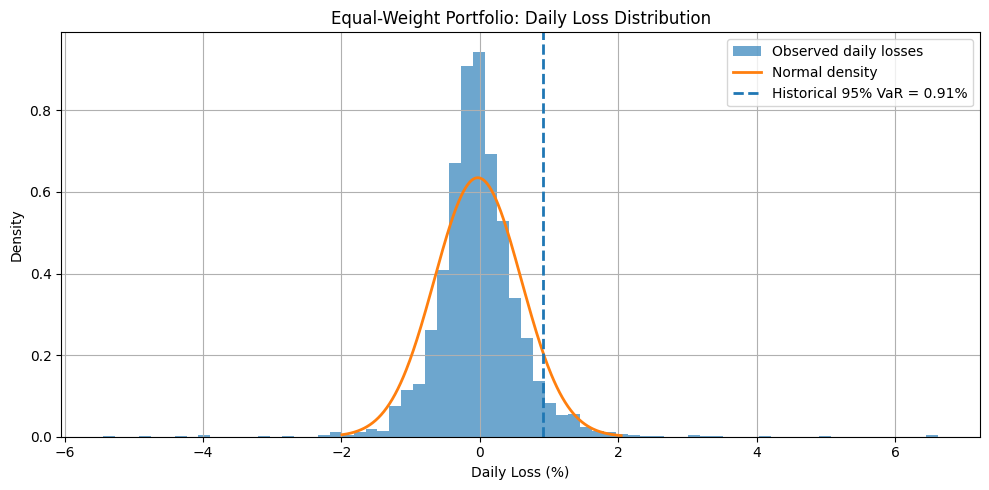

In [ ]:
# ============================================================
# EQUAL-WEIGHT PORTFOLIO: LOSS DISTRIBUTION AND VaR
# ============================================================
#
# This chart compares the observed distribution of daily
# portfolio losses with a fitted normal distribution.
#
# It also marks the historical 95% VaR threshold.
#
# Losses are defined as:
#
#       loss = -portfolio return
#
# A positive loss represents a decline in portfolio value.
# ============================================================

# Convert daily portfolio returns into daily losses.
losses = -equal_weight_returns

# Create the figure and axes.
fig, ax = plt.subplots(figsize=(10, 5))

# ------------------------------------------------------------
# 1. PLOT OBSERVED DAILY LOSSES
# ------------------------------------------------------------
# Multiply by 100 to display losses in percentage terms.
#
# density=True scales the histogram so that its total area
# equals 1. This makes it comparable with a probability density.
ax.hist(
    losses * 100,
    bins=70,
    density=True,
    alpha=0.65,
    label="Observed daily losses",
)

# ------------------------------------------------------------
# 2. CREATE A RANGE OF LOSS VALUES FOR THE NORMAL CURVE
# ------------------------------------------------------------
# Use the 0.5% and 99.5% empirical loss quantiles as plotting
# limits. This avoids extreme outliers dominating the x-axis.
x = np.linspace(
    losses.quantile(0.005),
    losses.quantile(0.995),
    400,
)

# Estimate the mean and standard deviation of daily returns.
mu = float(equal_weight_returns.mean())
sigma = float(equal_weight_returns.std(ddof=1))

# ------------------------------------------------------------
# 3. PLOT THE FITTED NORMAL DENSITY
# ------------------------------------------------------------
# The normal density is fitted to returns, but the chart shows
# losses. Since loss = -return, evaluate the normal density at -x.
#
# Divide by 100 to convert the density scale from decimal returns
# to percentage losses.
ax.plot(
    x * 100,
    norm.pdf(-x, loc=mu, scale=sigma) / 100,
    linewidth=2,
    label="Normal density",
)

# ------------------------------------------------------------
# 4. MARK THE HISTORICAL 95% VaR
# ------------------------------------------------------------
# Calculate the historical 95% VaR from observed losses.
var_95, _ = historical_var_cvar(
    losses=losses,
    confidence=0.95,
)

# Add a vertical line at the VaR threshold.
ax.axvline(
    var_95 * 100,
    linestyle="--",
    linewidth=2,
    label=f"Historical 95% VaR = {var_95 * 100:.2f}%",
)

# ------------------------------------------------------------
# 5. FORMAT AND DISPLAY THE CHART
# ------------------------------------------------------------
ax.set_title("Equal-Weight Portfolio: Daily Loss Distribution")
ax.set_xlabel("Daily Loss (%)")
ax.set_ylabel("Density")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STRESS TESTING AND TAIL-RISK DIAGNOSTICS
# ============================================================
#
# This section has two parts:
#
#   1. Hypothetical stress scenarios
#      - Applies predefined asset shocks to each portfolio.
#      - Calculates the resulting portfolio return and loss.
#
#   2. Historical tail diagnostics
#      - Examines the worst observed daily returns.
#      - Reports return percentiles, skewness, and excess kurtosis.
#
# The stress shocks below are illustrative hypothetical scenarios.
# They are not forecasts and do not have assigned probabilities.
# ============================================================

# ------------------------------------------------------------
# 1. DEFINE HYPOTHETICAL STRESS SCENARIOS
# ------------------------------------------------------------
#
# Each value is a hypothetical one-period price shock.
# For example, -0.20 means a hypothetical 20% decline.
#
# The asset order must match:
#   SPY, VXUS, IEF, LQD, GLD, VNQ
# ------------------------------------------------------------

stress_scenarios = pd.DataFrame(
    {
        "SPY": [-0.20, -0.15, -0.25],
        "VXUS": [-0.22, -0.12, -0.25],
        "IEF": [0.05, -0.15, -0.05],
        "LQD": [-0.08, -0.15, -0.10],
        "GLD": [0.10, 0.08, -0.05],
        "VNQ": [-0.25, -0.18, -0.20],
    },
    index=[
        "Equity market crash",
        "Inflation and rising rates",
        "Broad sell-off across assets",
    ],
)

# Ensure the shock columns match the portfolio asset order.
stress_scenarios = stress_scenarios.reindex(columns=asset_names)

# Display the hypothetical asset shocks.
display(stress_scenarios)


# ------------------------------------------------------------
# 2. APPLY STRESS SHOCKS TO EACH PORTFOLIO
# ------------------------------------------------------------

# Create an empty list to store stress-test results.
stress_rows = []

# Define the portfolios to stress test.
portfolios = {
    "Equal-weight": equal_weights,
    "Global Minimum Variance": gmv_weights,
}

# Loop through each hypothetical scenario.
for scenario_name, asset_shocks in stress_scenarios.iterrows():

    # Loop through each portfolio.
    for portfolio_name, weights in portfolios.items():

        # Portfolio scenario return is the weighted sum of asset shocks:
        #       portfolio return = w' * shock vector
        portfolio_return = float(
            weights @ asset_shocks.to_numpy()
        )

        # Portfolio loss is the negative of the scenario return.
        portfolio_loss = -portfolio_return

        # Save the result for this scenario and portfolio.
        stress_rows.append({
            "Scenario": scenario_name,
            "Portfolio": portfolio_name,
            "Portfolio Return (%)": portfolio_return * 100,
            "Portfolio Loss (%)": portfolio_loss * 100,
        })

# Combine all stress-test results into one DataFrame.
stress_results = pd.DataFrame(stress_rows)

# Display the stress-test results.
display(stress_results.round(3))


# ------------------------------------------------------------
# 3. HISTORICAL TAIL-RISK DIAGNOSTICS
# ------------------------------------------------------------
#
# These statistics describe the observed daily return
# distributions of each portfolio.
#
#   - Worst daily return: most negative observed return.
#   - 1st percentile: return exceeded by 99% of observations.
#   - 5th percentile: return exceeded by 95% of observations.
#   - Skewness: measures asymmetry of the return distribution.
#   - Excess kurtosis: measures tail thickness relative to a
#     normal distribution.
# ------------------------------------------------------------

tail_diagnostics = pd.DataFrame(
    {
        "Equal-weight": {
            "Worst Daily Return (%)":
                equal_weight_returns.min() * 100,

            "1st Percentile Return (%)":
                equal_weight_returns.quantile(0.01) * 100,

            "5th Percentile Return (%)":
                equal_weight_returns.quantile(0.05) * 100,

            "Skewness":
                equal_weight_returns.skew(),

            "Excess Kurtosis":
                equal_weight_returns.kurt(),
        },

        "Global Minimum Variance": {
            "Worst Daily Return (%)":
                gmv_portfolio_returns.min() * 100,

            "1st Percentile Return (%)":
                gmv_portfolio_returns.quantile(0.01) * 100,

            "5th Percentile Return (%)":
                gmv_portfolio_returns.quantile(0.05) * 100,

            "Skewness":
                gmv_portfolio_returns.skew(),

            "Excess Kurtosis":
                gmv_portfolio_returns.kurt(),
        },
    }
).T

# Display the tail-risk diagnostics.
display(tail_diagnostics.round(3))

,GLD,IEF,LQD,SPY,VNQ,VXUS
Equity market crash,0.10,0.05,-0.08,-0.20,-0.25,-0.22
Inflation and rising rates,0.08,-0.15,-0.15,-0.15,-0.18,-0.12
Broad sell-off across assets,-0.05,-0.05,-0.10,-0.25,-0.20,-0.25


,Scenario,Portfolio,Portfolio Return (%),Portfolio Loss (%)
0,Equity market crash,Equal-weight,-10.000,10.000
1,Equity market crash,Global Minimum Variance,0.979,-0.979
2,Inflation and rising rates,Equal-weight,-11.167,11.167
3,Inflation and rising rates,Global Minimum Variance,-14.910,14.910
4,Broad sell-off across assets,Equal-weight,-15.000,15.000
5,Broad sell-off across assets,Global Minimum Variance,-8.169,8.169


,Worst Daily Return (%),1st Percentile Return (%),5th Percentile Return (%),Skewness,Excess Kurtosis
Equal-weight,-6.621,-1.605,-0.909,-0.664,16.010
Global Minimum Variance,-2.084,-1.026,-0.583,-0.095,3.642


# Out-of sample testing

In [ ]:
# Define the date that separates training and testing data.
SPLIT_DATE = "2023-01-01"

# Define the rolling VaR estimation window.
VAR_WINDOW = 252

# Define the annual risk-free-rate proxy.
RISK_FREE_RATE = 0.04

print(f"Split date: {SPLIT_DATE}")
print(f"VaR window: {VAR_WINDOW} trading days")
print(f"Risk-free rate: {RISK_FREE_RATE:.2%}")

Split date: 2023-01-01
VaR window: 252 trading days
Risk-free rate: 4.00%


In [ ]:
# ============================================================
# OUT-OF-SAMPLE BACKTESTING: TRAIN/TEST SPLIT
# ============================================================
#
# This section tests portfolio allocations on data that comes
# after the training period.
#
# Training data:
#   Used to estimate the GMV portfolio weights.
#
# Testing data:
#   Used to evaluate how those weights performed afterward.
#
# The split must be chronological to avoid look-ahead bias.
# ============================================================

# Convert the split date to a pandas timestamp.
split_date = pd.Timestamp(SPLIT_DATE)

# Training returns: all observations before the split date.
train_returns = returns.loc[returns.index < split_date].copy()

# Testing returns: all observations on or after the split date.
test_returns = returns.loc[returns.index >= split_date].copy()

# Validate that both samples contain observations.
if train_returns.empty:
    raise ValueError("Training sample is empty.")

if test_returns.empty:
    raise ValueError("Testing sample is empty.")

# Display the train/test date ranges.
print(
    f"Training: {train_returns.index.min().date()} "
    f"to {train_returns.index.max().date()} "
    f"({len(train_returns)} observations)"
)

print(
    f"Testing:  {test_returns.index.min().date()} "
    f"to {test_returns.index.max().date()} "
    f"({len(test_returns)} observations)"
)

Training: 2015-01-05 to 2022-12-30 (2013 observations)
Testing:  2023-01-03 to 2026-10-14 (949 observations)


In [ ]:
# ============================================================
# ESTIMATE PORTFOLIO WEIGHTS USING TRAINING DATA ONLY
# ============================================================

def optimize_gmv_weights(window):
    """
    Estimate global minimum-variance portfolio weights.

    The optimizer minimizes estimated portfolio variance:

        minimize w' * covariance * w

    subject to:
        - Weights sum to 1.
        - Each weight is between 0 and 1.

    Parameters
    ----------
    window : DataFrame
        Historical asset returns used for estimation.

    Returns
    -------
    numpy.ndarray
        GMV portfolio weights.
    """
    # Annualize the sample covariance matrix.
    covariance = (
        window.cov().to_numpy(dtype=float)
        * TRADING_DAYS
    )

    # Start from an equal-weight portfolio.
    n= len(asset_names)
    initial_weights = np.ones(len(asset_names)) / len(asset_names)

    # Optimize portfolio variance.
    result = minimize(
        fun=lambda w: float(w @ covariance @ w),
        x0=initial_weights,
        method="SLSQP",
        bounds=[(0, 1)] * n,
        constraints=[
            {
                "type": "eq",
                "fun": lambda w: np.sum(w) - 1,
            }
        ],
        options={
            "maxiter": 2000,
            "ftol": 1e-12,
        },
    )

    # Raise an error if optimization fails.
    if not result.success:
        raise RuntimeError(result.message)

    return result.x


# Equal-weight allocation: no optimization required.
train_equal_weights = np.ones(len(asset_names)) / len(asset_names)

# GMV allocation: estimated using training returns only.
train_gmv_weights = optimize_gmv_weights(train_returns)

# Combine both allocations into one table.
training_weights = pd.DataFrame(
    {
        "Equal-weight": train_equal_weights,
        "Training GMV": train_gmv_weights,
    },
    index=asset_names,
)

display(training_weights.round(4))

,Equal-weight,Training GMV
GLD,0.1667,0.0000
IEF,0.1667,0.8401
LQD,0.1667,0.0000
SPY,0.1667,0.0851
VNQ,0.1667,0.0000
VXUS,0.1667,0.0748


In [ ]:
# ============================================================
# APPLY TRAINING WEIGHTS TO OUT-OF-SAMPLE RETURNS
# ============================================================
#
# The training weights are applied to testing-period returns.
# The testing returns do not influence the weight estimates.
# ============================================================

# Calculate daily testing-period portfolio returns.
test_portfolio_returns = pd.DataFrame(
    {
        "Equal-weight": test_returns @ train_equal_weights,
        "Training GMV": test_returns @ train_gmv_weights,
    },
    index=test_returns.index,
)

# Display the first few out-of-sample portfolio returns.
display(test_portfolio_returns.head())

,Equal-weight,Training GMV
Date,,
2023-01-03,0.004442,0.006726
2023-01-04,0.011966,0.008375
2023-01-05,-0.010271,-0.002830
2023-01-06,0.020202,0.014515
2023-01-09,0.002322,0.002490


In [ ]:
# ============================================================
# OUT-OF-SAMPLE PERFORMANCE METRICS
# ============================================================

def calculate_performance_metrics(
    series,
    risk_free_rate=RISK_FREE_RATE,
):
    """
    Calculate out-of-sample performance metrics.

    Parameters
    ----------
    series : array-like or Series
        Daily portfolio returns.
    risk_free_rate : float
        Annual risk-free-rate proxy.

    Returns
    -------
    pandas.Series
        Performance metrics.
    """
    # Clean the return series.
    r = pd.Series(series).dropna()

    if r.empty:
        raise ValueError(
            "Cannot calculate performance metrics on empty returns."
        )

    # Calculate cumulative growth of $1.
    growth = (1 + r).cumprod()

    # Calculate annualized return.
    years = len(r) / TRADING_DAYS

    annualized_return = float(
        growth.iloc[-1] ** (1 / years) - 1
    )

    # Calculate annualized volatility.
    annualized_volatility = float(
        r.std(ddof=1) * np.sqrt(TRADING_DAYS)
    )

    # Calculate Sharpe ratio using annualized figures.
    sharpe_ratio = (
        (annualized_return - risk_free_rate)
        / annualized_volatility
        if annualized_volatility > 0
        else np.nan
    )

    # Add an initial wealth value of 1 before calculating drawdowns.
    growth_with_start = pd.concat(
        [
            pd.Series(
                [1.0],
                index=[r.index[0] - pd.Timedelta(days=1)],
            ),
            growth,
        ]
    )

    # Calculate drawdown relative to the running wealth peak.
    drawdown = (
        growth_with_start / growth_with_start.cummax() - 1
    )

    return pd.Series(
        {
            "Cumulative Return (%)":
                (growth.iloc[-1] - 1) * 100,

            "Annualized Return (%)":
                annualized_return * 100,

            "Annualized Volatility (%)":
                annualized_volatility * 100,

            "Sharpe Ratio":
                sharpe_ratio,

            "Maximum Drawdown (%)":
                drawdown.min() * 100,
        }
    )


# Calculate performance for each testing-period portfolio.
out_of_sample_summary = pd.DataFrame(
    {
        name: calculate_performance_metrics(
            test_portfolio_returns[name]
        )
        for name in test_portfolio_returns.columns
    }
).T

# Display the performance comparison.
display(out_of_sample_summary.round(3))

,Cumulative Return (%),Annualized Return (%),Annualized Volatility (%),Sharpe Ratio,Maximum Drawdown (%)
Equal-weight,57.066,12.737,9.485,0.921,-8.752
Training GMV,18.546,4.621,6.559,0.095,-8.484


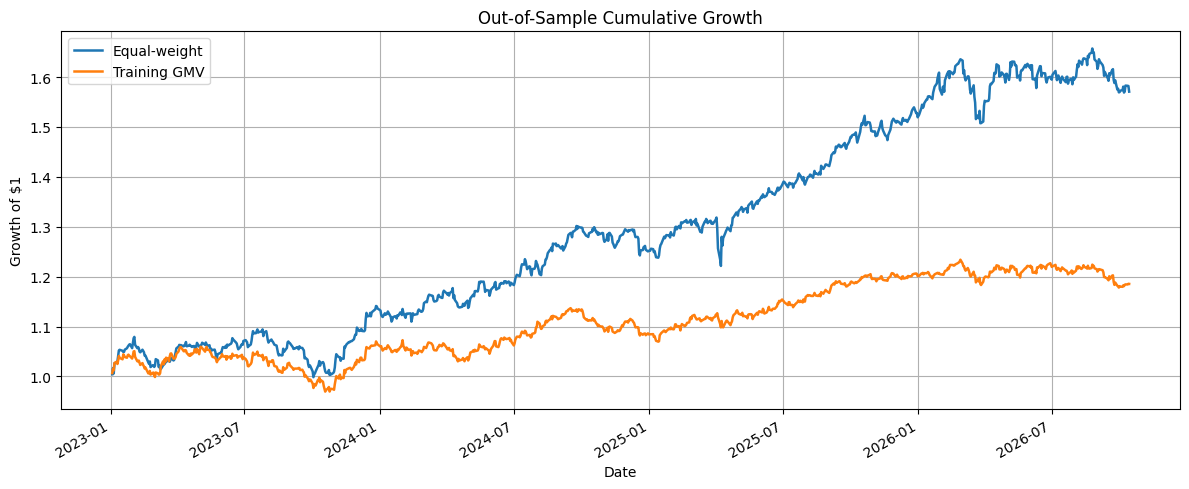

In [ ]:
# ============================================================
# PLOT OUT-OF-SAMPLE CUMULATIVE PERFORMANCE
# ============================================================

# Calculate growth of $1 for each portfolio.
out_of_sample_wealth = (1 + test_portfolio_returns).cumprod()

# Plot cumulative wealth.
ax = out_of_sample_wealth.plot(
    linewidth=1.8,
    figsize=(12, 5),
)

ax.set_title("Out-of-Sample Cumulative Growth")
ax.set_xlabel("Date")
ax.set_ylabel("Growth of $1")
ax.grid(True)

plt.tight_layout()
plt.show()

#Backtest rolling historical VaR

In [ ]:
# ============================================================
# ROLLING HISTORICAL VaR BACKTEST
# ============================================================
#
# For each day, estimate VaR using the previous VAR_WINDOW
# daily losses. Then compare the VaR forecast with the actual
# loss on the following day.
#
# An exception occurs when:
#
#       actual loss > forecast VaR
#
# At 95% confidence, the expected exception rate is 5%.
# ============================================================

def rolling_historical_var_backtest(
    series,
    window=VAR_WINDOW,
    confidence=0.95,
):
    """
    Backtest a rolling historical VaR forecast.

    Parameters
    ----------
    series : array-like or Series
        Daily portfolio returns.
    window : int
        Number of past daily losses used to estimate VaR.
    confidence : float
        VaR confidence level.

    Returns
    -------
    tuple
        (VaR backtest DataFrame, exception count, valid observations)
    """
    # Clean the return series.
    r = pd.Series(series).dropna()

    # Convert returns into losses.
    losses = -r

    # Estimate VaR using only past losses.
    #
    # shift(1) ensures that today's loss is not used to estimate
    # today's VaR forecast.
    var = (
        losses
        .shift(1)
        .rolling(
            window=window,
            min_periods=window,
        )
        .quantile(confidence)
    )

    # Identify VaR exceptions.
    exceptions = losses > var

    # A forecast is valid only when enough history exists.
    valid = var.notna()

    # Count exceptions among valid forecasts.
    exception_count = int(
        (exceptions & valid).sum()
    )

    valid_count = int(valid.sum())

    # Create a detailed daily backtest table.
    backtest_frame = pd.DataFrame(
        {
            "Loss": losses,
            "VaR": var,
            "Exception": exceptions,
            "Valid": valid,
        }
    )

    return (
        backtest_frame,
        exception_count,
        valid_count,
    )


# Store detailed VaR backtests and summary statistics.
backtest_frames = {}
summary_rows = []

# Backtest VaR for each testing-period portfolio.
for portfolio_name in test_portfolio_returns.columns:

    (
        backtest_frame,
        exception_count,
        valid_count,
    ) = rolling_historical_var_backtest(
        series=test_portfolio_returns[portfolio_name],
        window=VAR_WINDOW,
        confidence=0.95,
    )

    # Save the detailed daily results.
    backtest_frames[portfolio_name] = backtest_frame

    # Save summary results.
    summary_rows.append(
        {
            "Portfolio": portfolio_name,
            "VaR Window": VAR_WINDOW,
            "Confidence": "95%",
            "Exceptions": exception_count,
            "Valid Observations": valid_count,
            "Exception Rate (%)": (
                100 * exception_count / valid_count
                if valid_count > 0
                else np.nan
            ),
            "Expected Rate (%)": 5.0,
        }
    )

# Combine VaR backtest summaries.
var_backtest_summary = pd.DataFrame(summary_rows).set_index(
    "Portfolio"
)

# Display the VaR backtest summary.
display(var_backtest_summary.round(3))

,VaR Window,Confidence,Exceptions,Valid Observations,Exception Rate (%),Expected Rate (%)
Portfolio,,,,,,
Equal-weight,252,95%,40,697,5.739,5.0
Training GMV,252,95%,35,697,5.022,5.0


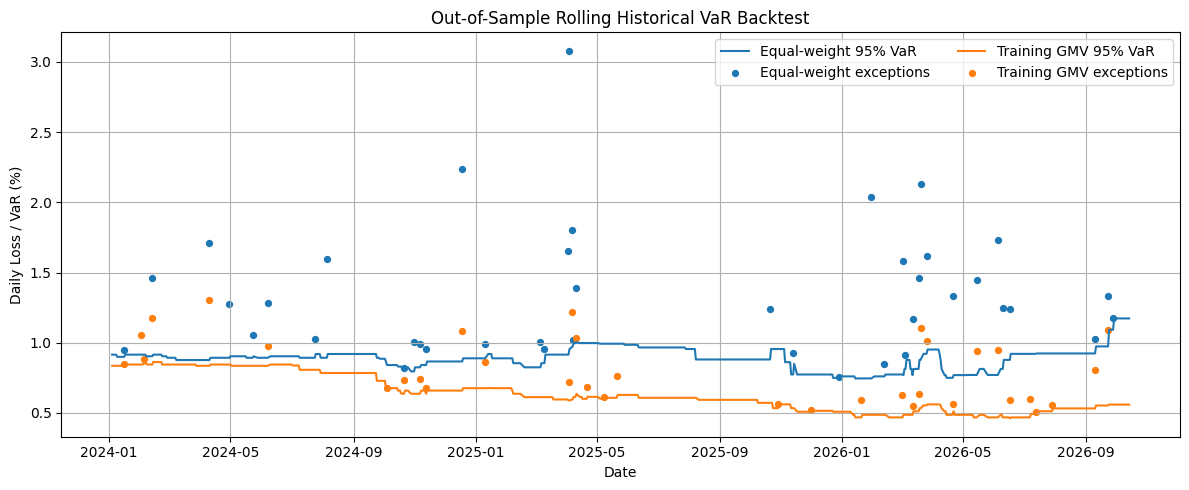

In [ ]:
# ============================================================
# PLOT ROLLING VaR FORECASTS AND EXCEPTIONS
# ============================================================

fig, ax = plt.subplots(figsize=(12, 5))

# Plot VaR forecasts and exceptions for each portfolio.
for portfolio_name, frame in backtest_frames.items():

    # Plot the rolling VaR forecast.
    ax.plot(
        frame.index,
        frame["VaR"] * 100,
        label=f"{portfolio_name} 95% VaR",
    )

    # Identify valid VaR exceptions.
    exceptions = frame["Valid"] & frame["Exception"]

    # Plot exception days.
    ax.scatter(
        frame.index[exceptions],
        frame.loc[exceptions, "Loss"] * 100,
        s=18,
        label=f"{portfolio_name} exceptions",
    )

ax.set_title("Out-of-Sample Rolling Historical VaR Backtest")
ax.set_xlabel("Date")
ax.set_ylabel("Daily Loss / VaR (%)")
ax.legend(ncol=2)
ax.grid(True)

plt.tight_layout()
plt.show()

#Test GMV sensitivity to training-window length python


,1-year training,2-year training,3-year training
Asset,,,
GLD,0.1080,0.0347,0.0136
IEF,0.7797,0.8270,0.8556
LQD,0.0000,0.0000,0.0000
SPY,0.0000,0.0000,0.0336
VNQ,0.0000,0.0000,0.0000
VXUS,0.1123,0.1383,0.0972


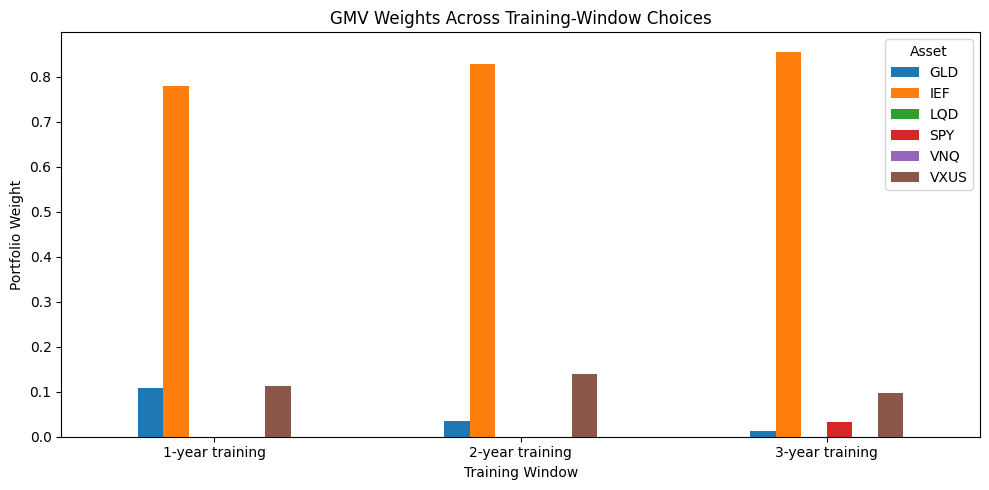

In [ ]:
# ============================================================
# GMV WEIGHT SENSITIVITY TO TRAINING-WINDOW LENGTH
# ============================================================
#
# This checks whether GMV weights are stable when the training
# window changes.
#
# A large change in weights across reasonable training windows
# may indicate sensitivity to estimation error.
# ============================================================

# Use only training-period data.
historical_training = returns.loc[
    returns.index < split_date
].copy()

# Define alternative training-window lengths.
training_window_choices = {
    "1-year training": 252,
    "2-year training": 504,
    "3-year training": 756,
}

# Store GMV weights for each training-window choice.
sensitivity = {}

for label, window_length in training_window_choices.items():

    # Select the most recent observations from the training sample.
    sample = historical_training.tail(window_length)

    # Require a minimum number of observations.
    if len(sample) >= 60:
        sensitivity[label] = optimize_gmv_weights(sample)

# Combine GMV weights across training windows.
weight_sensitivity = pd.DataFrame(
    sensitivity,
    index=asset_names,
)

weight_sensitivity.index.name = "Asset"

# Display the sensitivity results.
display(weight_sensitivity.round(4))

# Plot the GMV weights across training-window choices.
if not weight_sensitivity.empty:

    ax = weight_sensitivity.T.plot(
        kind="bar",
        figsize=(10, 5),
    )

    ax.set_title(
        "GMV Weights Across Training-Window Choices"
    )

    ax.set_xlabel("Training Window")
    ax.set_ylabel("Portfolio Weight")
    ax.tick_params(axis="x", rotation=0)

    plt.tight_layout()
    plt.show()

## Out-of-Sample Backtesting

This section evaluates portfolio performance using **out-of-sample returns** that were not used to estimate the portfolio weights. The objective is to assess whether the Global Minimum-Variance (GMV) portfolio maintains its risk characteristics on unseen data and how its performance compares with a simple equal-weight benchmark.

Out-of-sample testing helps reduce look-ahead bias by ensuring that portfolio weights are determined using historical information available before the testing period begins.

---

### 1. Chronological Train/Test Split

The return history is divided into two consecutive periods:

$$
\underbrace{\text{Training Period}}_{\text{Estimate portfolio weights}}
\quad \longrightarrow \quad
\underbrace{\text{Testing Period}}_{\text{Evaluate performance}}
$$

- **Training period:** Used to estimate the asset return covariance matrix and optimize the GMV portfolio weights.
- **Testing period:** Used to evaluate portfolio performance using the previously estimated weights.

The portfolio weights are fixed at the end of the training period and applied to returns observed during the testing period. This ensures that the testing results do not influence the initial portfolio construction.

---

### 2. Portfolio Construction

Two long-only, fully invested portfolios are evaluated:

1. **Equal-Weight Portfolio:** Allocates the same proportion of capital to each asset.
2. **Training-Period GMV Portfolio:** Minimizes estimated portfolio variance using only training-period return data.

For a portfolio containing \(N\) assets, the equal-weight allocation is:

$$
w_i = \frac{1}{N},
\qquad i = 1,\ldots,N
$$

The GMV portfolio is constructed by solving the following optimization problem:

$$
\min_{\mathbf{w}}
\quad
\mathbf{w}^{\top}\boldsymbol{\Sigma}_{\text{train}}\mathbf{w}
$$

subject to:

$$
\sum_{i=1}^{N} w_i = 1
$$

$$
w_i \geq 0,
\qquad i = 1,\ldots,N
$$

where:

- \(\mathbf{w}\) is the vector of portfolio weights.
- \(\boldsymbol{\Sigma}_{\text{train}}\) is the covariance matrix estimated from training-period returns.
- The full-investment constraint requires all available capital to be allocated.
- The long-only constraint prohibits short positions.

**Important:** The GMV weights are estimated once using the training data. They are not recalculated using testing-period returns.

---

### 3. Out-of-Sample Performance Evaluation

After portfolio construction, the estimated weights are applied to the testing-period asset returns to calculate daily portfolio returns.

For testing day \(t\), portfolio return is:

$$
R_{p,t} = \mathbf{w}^{\top}\mathbf{r}_t
$$

where:

- \(R_{p,t}\) is the portfolio return on day \(t\).
- \(\mathbf{w}\) is the portfolio weight vector estimated during training.
- \(\mathbf{r}_t\) is the vector of asset returns observed on day \(t\).

The following performance measures are used to compare the two portfolios.

| Metric | Purpose |
|---|---|
| Cumulative return | Measures the total return over the testing period. |
| Annualized return | Expresses performance as an annual rate. |
| Annualized volatility | Measures the variability of portfolio returns. |
| Sharpe ratio | Measures excess return relative to return volatility, using a specified risk-free rate. |
| Maximum drawdown | Measures the largest peak-to-trough decline in portfolio value. |

These metrics provide complementary perspectives on portfolio performance. For example, a portfolio may have lower volatility but also lower returns, so no single measure fully describes its performance.

The comparison helps determine whether the GMV portfolio delivered a different out-of-sample risk-return profile from the equal-weight benchmark.

---

### 4. Rolling Historical Value at Risk (VaR) Backtest

This section evaluates the accuracy of historical Value at Risk (VaR) forecasts during the testing period.

For each testing day, historical VaR is estimated using the previous `VAR_WINDOW` daily portfolio losses. The forecast is then compared with the actual loss observed on the following day.

Let \(L_t\) represent the portfolio loss on day \(t\), expressed as a positive number when the portfolio loses value. At confidence level \(c\), the historical VaR forecast is denoted by \(\operatorname{VaR}_{c,t}\).

A VaR exception occurs when:

$$
L_t > \operatorname{VaR}_{c,t}
$$

For a 95% VaR model, the nominal probability of exceeding the VaR threshold is:

$$
1-c = 1-0.95 = 0.05 = 5\%
$$

Therefore, under appropriate calibration and distributional assumptions, approximately 5% of observations are expected to exceed the 95% VaR threshold over the long run.

The observed exception rate is calculated as:

$$
\text{Exception Rate}
=
\frac{\text{Number of VaR Exceptions}}
{\text{Number of Valid VaR Forecasts}}
$$

**Interpretation:**

- An exception rate substantially above 5% may indicate that the model underestimates downside risk.
- An exception rate substantially below 5% may indicate that the model is conservative, although a low exception rate alone does not establish that the model is well calibrated.
- The timing and clustering of exceptions also matter, because exceptions concentrated during periods of market stress may reveal weaknesses in the risk model.

The expected exception rate is a long-run benchmark, not a requirement that exactly 5% of a short testing sample must breach VaR. Formal statistical tests can help determine whether the observed exceptions are consistent with the model's stated confidence level.

---

### 5. Training-Window Sensitivity Analysis

GMV portfolio weights depend on the historical observations used to estimate the covariance matrix. To investigate this dependence, the optimization is repeated using different training-window lengths:

- **1-year training window**
- **2-year training window**
- **3-year training window**

For each window, the covariance matrix is re-estimated and the GMV portfolio is optimized using the same long-only and full-investment constraints.

The resulting portfolio weights are then compared across estimation windows.

**Interpretation:**

- Similar weights across windows suggest that the allocation is relatively stable with respect to the selected estimation period.
- Large differences in weights suggest that the allocation is sensitive to the estimation window and may be affected by covariance-estimation error or changing market conditions.

A longer training window provides more historical observations but may include market conditions that are less representative of the testing period. A shorter window may better reflect recent conditions but can produce noisier covariance estimates.

This analysis therefore highlights a practical trade-off between using more historical data and adapting to changing market relationships.

---

### 6. Methodological Considerations

Several factors should be considered when interpreting the results:

- **No look-ahead bias:** Portfolio weights must be estimated exclusively from data available before the testing period.
- **Consistent asset universe:** Both portfolios should use the same assets and testing dates to ensure a fair comparison.
- **Consistent return frequency:** Annualization conventions must match the frequency of the return data.
- **Risk-free rate:** The Sharpe ratio should use a risk-free rate that is consistent with the return frequency and evaluation period.
- **Transaction costs:** Unless explicitly modeled, reported performance does not account for trading fees, bid-ask spreads, or rebalancing costs.
- **VaR window alignment:** Each VaR forecast must use only losses available before the loss being evaluated. The forecast must not incorporate the testing day's realized loss.
- **Training-window comparability:** When comparing 1-year, 2-year, and 3-year windows, the testing period should be aligned where possible so differences are not simply caused by evaluating different market conditions.

---

### Conclusion

Out-of-sample backtesting evaluates whether a portfolio construction method produces useful results beyond the data used to estimate it.

The equal-weight portfolio provides a transparent benchmark, while the GMV portfolio uses historical covariance estimates to minimize portfolio variance. Comparing their out-of-sample returns, volatility, Sharpe ratios, and maximum drawdowns helps reveal how their risk-return profiles differ.

The rolling VaR backtest evaluates whether the risk forecasts are reasonably calibrated, while the training-window sensitivity analysis examines how stable the optimized allocation is under different historical estimation periods.

Taken together, these analyses provide a more complete assessment of portfolio construction than relying on in-sample optimization results alone. However, strong historical backtest results do not guarantee future performance.

In [ ]:
# SAVE NOTEBOOK 1 OUTPUTS TO GOOGLE DRIVE

#prices.to_csv(f"{DATA_RAW_DIR}/adjusted_prices.csv")
#returns.to_csv(f"{DATA_PROCESSED_DIR}/daily_returns.csv")

#asset_summary.to_csv(f"{OUTPUTS_DIR}/asset_summary.csv", index=False)
#correlation_matrix.to_csv(f"{OUTPUTS_DIR}/correlation_matrix.csv")
#cov_matrix.to_csv(f"{OUTPUTS_DIR}/annualized_covariance_matrix.csv")

#print("Saved files to:")
#print(f"{DATA_RAW_DIR}/adjusted_prices.csv")
#print(f"{DATA_PROCESSED_DIR}/daily_returns.csv")
#print(f"{OUTPUTS_DIR}/asset_summary.csv")
#print(f"{OUTPUTS_DIR}/correlation_matrix.csv")
#print(f"{OUTPUTS_DIR}/annualized_covariance_matrix.csv")